# 华盛顿科伦比亚特区犯罪案件分析

#### 张雪琰 11811736

犯罪是当今人类社会中常见的行为，其与经济、文化、政治、科技以及人民幸福指数有着千丝万缕的联系。为了维护社会的秩序、降低犯罪率，犯罪与人类社会内部的联系应当被深入调查。

## 1. 数据源
本案例中的犯罪数据基于 https://dcatlas.dcgis.dc.gov/crimecards/ 中的数据。该犯罪数据包含 2008 年至 2021 年 1 月的449203个案例，每个案例包含29个变量，包含了该案件发生的地点、时间、性质、手段等详细信息，以及犯案地区的若干信息，如经纬度、街区、PSA (Police Service Area) 等。

In [1]:
import pandas as pd
import numpy as np
import pandas as pd
import math
import seaborn as sns
import re
import time
import datetime
import folium

from pandas import Series
from matplotlib import pyplot as plt
from textwrap import fill

from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial import distance
from scipy.stats import chi2_contingency

from matplotlib.colors import LogNorm
from matplotlib.colors import FuncNorm

from sklearn import preprocessing
from sklearn import model_selection
from sklearn.model_selection import TimeSeriesSplit

from sklearn import metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mean_absolute_error

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


## 2. 数据预处理与清洗

In [2]:
cr = pd.read_csv('DC_Crime.csv')
print(cr.shape)
cr.head(3)

(449203, 29)


,NEIGHBORHOOD_CLUSTER,CENSUS_TRACT,offensegroup,LONGITUDE,END_DATE,offense-text,SHIFT,YBLOCK,DISTRICT,WARD,...,BLOCK,START_DATE,CCN,OFFENSE,OCTO_RECORD_ID,ANC,REPORT_DAT,METHOD,location,LATITUDE
0,cluster 21,8702.0,property,-77.003574,2017-04-29T08:00:23.000,theft f/auto,day,138139.0,5.0,5.0,...,150 - 299 block of q street ne,2017-04-29T01:30:14.000,17070672,theft f/auto,17070672-01,5E,2017-04-29T13:49:31.000Z,others,"38.911121322949178,-77.003576581965632",38.911114
1,cluster 16,1600.0,property,-77.026557,2017-04-29T08:30:37.000,theft f/auto,day,146051.0,4.0,4.0,...,7600 - 7699 block of georgia avenue nw,2017-04-29T02:30:10.000,17070675,theft f/auto,17070675-01,4A,2017-04-29T14:38:59.000Z,others,"38.982391883146363,-77.026559339798794",38.982384
2,cluster 8,4702.0,property,-77.020913,2017-04-29T11:10:57.000,theft/other,day,137185.0,1.0,6.0,...,600 - 699 block of k street nw,2017-04-29T10:43:33.000,17070714,theft/other,17070714-01,6E,2017-04-29T15:19:02.000Z,others,"38.902525540064957,-77.020915170313728",38.902518


其中 CCN 是案件编号，主要用于案件识别，对后续模型构建的直接贡献有限，所以删去。分别有三列描述案发详细地点的数据，分别是 LATITUDE、LONGITUDE 和 location。由于前两列足以描述案发地点，此处删去 location。

同理，在 offensekey 中的信息同时包含 OFFENSE 、 offense-text 和 offensegroup 。考虑到后续分析，此处删去“ offense-text ”。

In [3]:
del cr["CCN"]
del cr["location"]
del cr["offense-text"]

cr["NEIGHBORHOOD_CLUSTER"] = cr["NEIGHBORHOOD_CLUSTER"].str.extract(r'cluster \s*(\d+)')
cr["NEIGHBORHOOD_CLUSTER"] = pd.to_numeric(cr["NEIGHBORHOOD_CLUSTER"])                               #将"CLUSTER_NEIGHBORHOOD"转为数值
cr["VOTING_PRECINCT"] = cr["VOTING_PRECINCT"].str.extract(r'precinct \s*(\d+)')
cr["VOTING_PRECINCT"] = pd.to_numeric(cr["VOTING_PRECINCT"])                                         #将"VOTING_PRECINCT"转为数值

In [4]:
year = cr["START_DATE"].astype("string").str.slice(0, 4)
cr = cr.loc[year.ge("2008")].copy()                                                                  #保留2008年及以后的案件

### 2.1 犯罪类型及手段

在 offensekey 中，案例被分到九种具体类型中；它们又分别被分为 violent 和 property 两大类，即暴力犯罪和财产犯罪。对于这种有多种类型的变量，可以利用柱状图和饼状图来直观地观察其数量与比例。

另一方面，通过比较，不难发现，OFFENSE 与 offensegroup 记录的内容完全重复。

In [5]:
print(cr["METHOD"].value_counts())
met_id = [0,1,2]
metkey = ["others","gun","knife"]
met_d = {key:value for key, value in zip(metkey,met_id)}
cr["METHOD"] = cr["METHOD"].map(met_d)

METHOD
others    408290
gun        26938
knife      13512
Name: count, dtype: int64


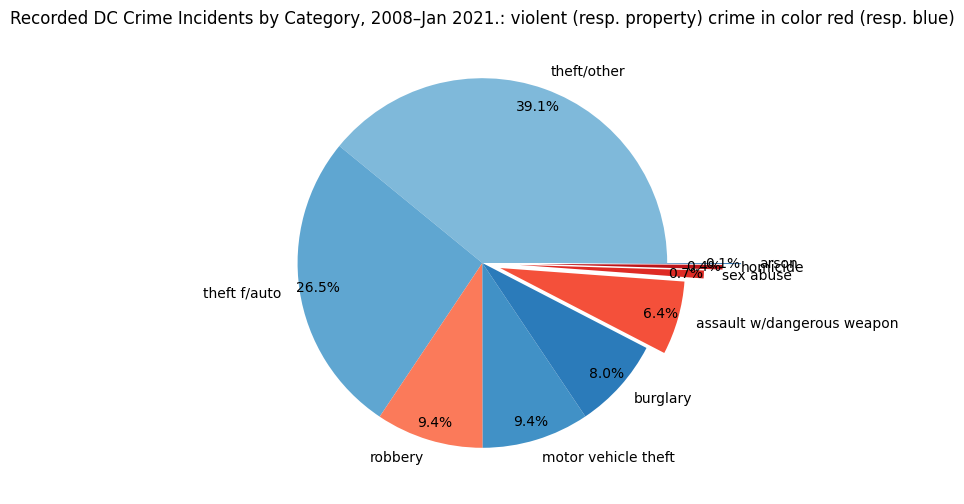

In [6]:
counts = cr["OFFENSE"].value_counts()

def crime_group(name):
    name = str(name).lower()

    if any(word in name for word in ["theft", "burglary", "arson"]):
        return "property"
    if any(word in name for word in ["robbery", "assault", "sex", "homicide"]):
        return "violent"

    return "other"

color_map = {}

for group, cmap_name in [
    ("property", "Blues"),
    ("violent", "Reds"),
]:
    group_labels = [
        crime_type for crime_type in counts.index
        if crime_group(crime_type) == group
    ]

    shades = np.linspace(0.45, 0.8, len(group_labels))
    cmap = plt.colormaps[cmap_name]

    for crime_type, shade in zip(group_labels, shades):
        color_map[crime_type] = cmap(shade)

colors = [color_map[crime_type] for crime_type in counts.index]

counts.plot.pie(
    colors=colors,
    labels=counts.index,
    autopct="%1.1f%%",
    figsize=(6, 6),
    pctdistance = 0.9,
    explode = (0,0,0,0,0,0.1,0.2,0.3,0.4)
)
plt.ylabel("")
plt.title("Recorded DC Crime Incidents by Category, 2008–Jan 2021.: violent (resp. property) crime in color red (resp. blue)")
plt.show()

 可见，在 449203 个样本中，财产犯罪有 373163 例，暴力犯罪有 76040 例，分别占比 83.07%和 16.93% 。财产犯罪占了绝大多数。

于此同时，在数据和图表中都可以看出，财产犯罪的数量远多于暴力犯罪，其中盗窃远多于其他犯罪类型。

### 2.2 犯罪发生的时间

犯罪发生的时间主要有两个方面：一是年份，二是轮班。在数据中，涵盖了 2008 年至 2021 年 1 月的数据，并将轮班分为日间、夜间、午夜三类。

首先，我们查看每个轮班的数据，并将其进行数字编码。日间编码为 0 ，夜间编码为 1 ，午夜编码为 2 。

In [7]:
print(cr.SHIFT.value_counts())
print("------------------------------------------------")
print(cr.SHIFT.value_counts()/len(cr))

SHIFT_dict = {"day":0,"evening":1,"midnight":2}
cr["SHIFT"] = cr["SHIFT"].map(SHIFT_dict)

SHIFT
evening     191806
day         169445
midnight     87489
Name: count, dtype: int64
------------------------------------------------
SHIFT
evening     0.427432
day         0.377602
midnight    0.194966
Name: count, dtype: float64


在所有案件中，发生在日间的一共有 169650 例，占比 37.77%；发生在夜间的一共 191978 例，占比 42.74%；发生在午夜的一共 87575 例，占比 19.50%。

In [8]:
# print(cr_time)

接下来，结合年份，将各个时间段的案件分类，并绘制出柱状图，方便观察。

    year  midnight  night    day
0   2008      6990  14114  12884
1   2009      6238  13031  12001
2   2010      5955  13599  12102
3   2011      6206  14143  12932
4   2012      6247  14486  14573
5   2013      6525  15046  14318
6   2014      6757  16172  15504
7   2015      7017  16255  14043
8   2016      7498  16686  13034
9   2017      6898  14014  12198
10  2018      7230  14381  12143
11  2019      7534  14924  11450
12  2020      5503  12291  10073
13  2021       891   2664   2190


C:\Users\ASUS\AppData\Local\Temp\ipykernel_185124\2322464610.py:25: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  sh.night[i] = sh.night[i] + sh.day[i]


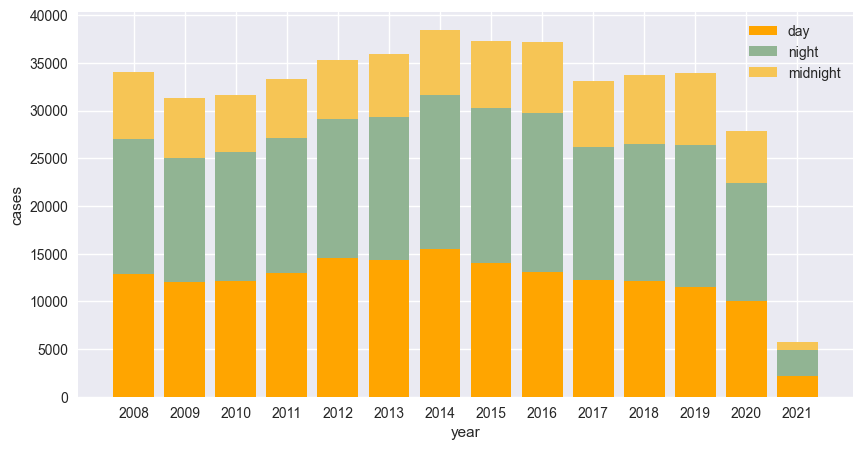

In [9]:
cr_time = cr[["YEAR","SHIFT"]]
time_day = cr_time[cr_time["SHIFT"] == 0].YEAR.value_counts()
time_night = cr_time[cr_time["SHIFT"] == 1].YEAR.value_counts()
time_mid = cr_time[cr_time["SHIFT"] == 2].YEAR.value_counts()

rows = []

for num in range(2008, 2022):
    rows.append({
        "year": num,
        "midnight": time_mid[num],
        "night": time_night[num],
        "day": time_day[num],
    })

sh = pd.DataFrame(rows, columns=["year", "midnight", "night", "day"])
print(sh)

plt.figure(figsize = (10,5))
plt.style.use('seaborn-v0_8')

plt.bar(sh.year,sh.day, align="center", color="orange",tick_label = sh.year, label="day")
plt.bar(sh.year,sh.night, align="center", bottom=sh.day, color="#91B493", label="night")
for i in range(0, len(sh)):
    sh.night[i] = sh.night[i] + sh.day[i]
plt.bar(sh.year,sh.midnight, align="center", bottom=sh.night, color="#F6C555", label="midnight")

plt.xlabel("year")
plt.ylabel("cases")
plt.legend()
plt.show()

从图上可以直观地看出，每一年中，发生在夜晚的案件最多，日间其次，午夜最少；后几年（从 2014 年至2021年1月），排除 2021 年由于只统计了少量数据而产生的影响，总的案件数量呈下降趋势，但整体变化不大。2020年犯罪数量骤减，可能与新冠病毒爆发有关。

接下来试分析每周周内每一天、月份、季节对犯罪数量的影响。

In [10]:
dayOfWeek_abbr = list()
dayOfWeek_num = list()


#从案发日期计算发生在星期几
def switch(x):
    return {
        "0": "Sun.",
        "1": "Mon.",
        "2": "Tue.",
        "3": "Wed.",
        "4": "Thur.",
        "5": "Fri.",
        "6": "Sat.",
    }.get(x)

for value in cr["START_DATE"]:
        date_num = datetime.datetime.strptime(
            str(value)[:10], "%Y-%m-%d"
        ).strftime("%w")

        dayOfWeek_abbr.append(switch(date_num))
        dayOfWeek_num.append(int(date_num))

In [11]:
abbr = ["Mon.","Tue.","Wed.","Thur.","Fri.","Sat.","Sun."]
days = pd.Series(index = abbr)

for index in days.index:
    days[index] = dayOfWeek_abbr.count(index)

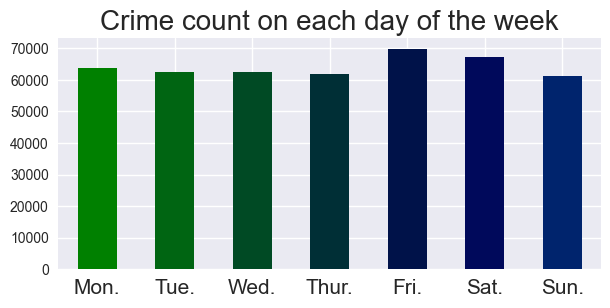

In [12]:
plt.style.use('seaborn-v0_8')

color = plt.cm.ocean(np.linspace(0, 1, 15))
days.plot.bar(color = color, figsize = (7,3))

plt.title('Crime count on each day of the week',fontsize = 20)

plt.yticks(fontsize = 10)
plt.xticks(rotation = 0,fontsize = 15)
plt.show()

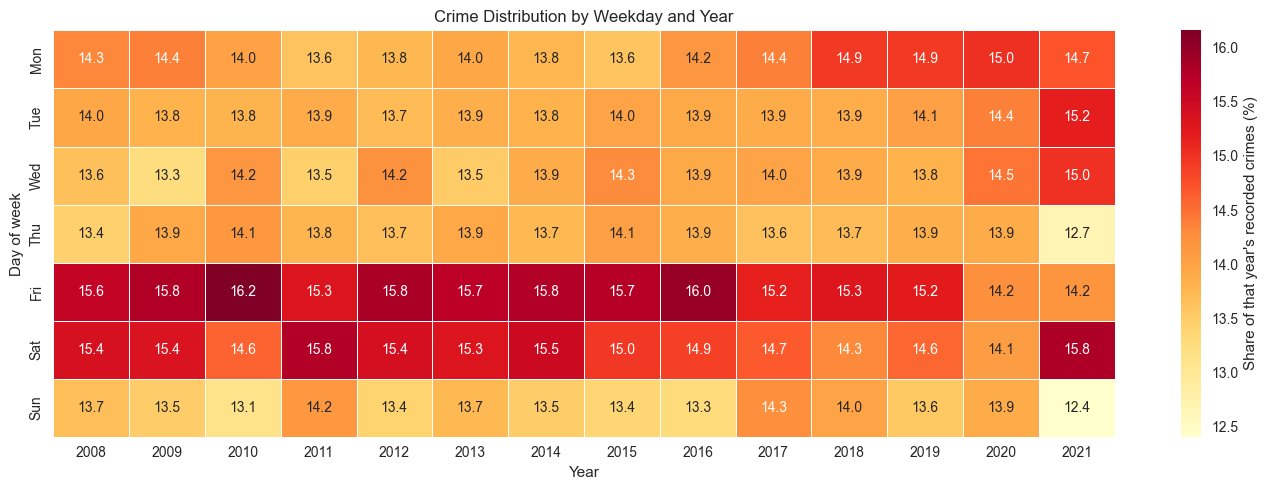

In [13]:
date = pd.to_datetime(cr["START_DATE"], errors="coerce")

temp = cr.loc[date.notna()].copy()
temp["year"] = date[date.notna()].dt.year
temp["weekday"] = date[date.notna()].dt.dayofweek 

weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# 每年各星期的案件数
counts = pd.crosstab(temp["weekday"], temp["year"])
counts = counts.reindex(range(7), fill_value=0)
counts.index = weekday_names

# 转为“每年内部占比”，方便比较年份之间星期分布
proportions = counts.div(counts.sum(axis=0), axis=1) * 100

plt.figure(figsize=(14, 5))
sns.heatmap(
    proportions,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Share of that year's recorded crimes (%)"}
)
plt.title("Crime Distribution by Weekday and Year")
plt.xlabel("Year")
plt.ylabel("Day of week")
plt.tight_layout()
plt.show()

2008–2019 年的案件分布在一周内存在一定差异，星期五和星期六的记录数量相对较多。2020 年各星期的分布则更接近平均。2021 年仅包含 1 月，因此不纳入跨年比较。

统计季节对犯罪的影响。

In [14]:
cr["SEASON"] = ''
season = list()

# 0:spring, 1:summer, 2:autumn, 3:winter
for i in range (len(cr)):
    temp = str(cr.iloc[i]["END_DATE"])
    if temp[0] == '2':
        month = int(''.join(temp[5:7]))
        if month <=2 or month == 12 :
            ss = "winter"
        elif month <= 5:
            ss = "spring"
        elif month <= 8:
            ss = "summer"
        else:
            ss = "autumn"
    else:
        ss = "unknown"
    season.append(ss)
        
cr["SEASON"] = season
cr["SEASON"].value_counts()

SEASON
summer     113112
autumn     110962
spring      99272
winter      98616
unknown     26778
Name: count, dtype: int64

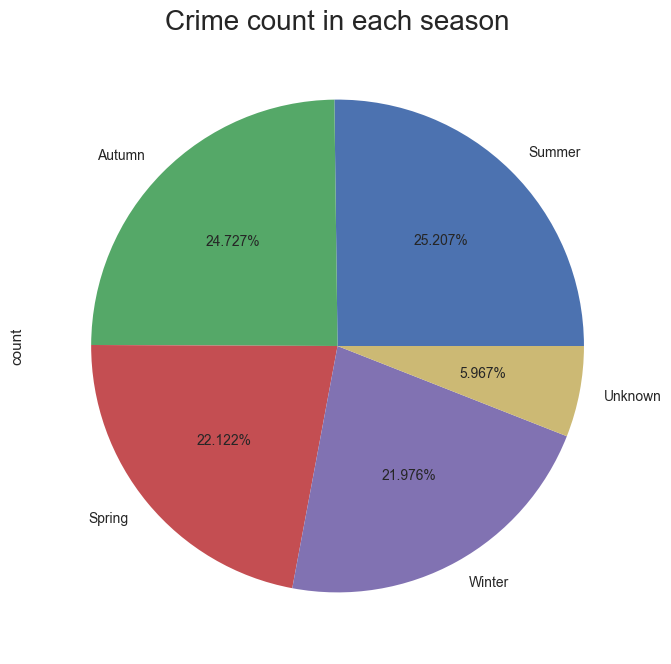

In [15]:
plt.style.use('seaborn-v0_8')

labels = ['Summer','Autumn','Spring','Winter','Unknown']
cr["SEASON"].value_counts().plot.pie(labels = labels, figsize = (15, 8),autopct = '%.3f%%')
plt.title('Crime count in each season',fontsize = 20)
plt.xticks(rotation = 90)
plt.show()

夏天和秋天的犯罪率比春天和冬天更高。但是总体上来说，影响并不大。

研究每天中的时间段对犯罪发生的影响。

In [16]:
start = cr["START_DATE"].astype("string")

cr["TIME"] = pd.to_numeric(
    start.str.slice(11, 13),
    errors="coerce"
).fillna(-1).astype(int)

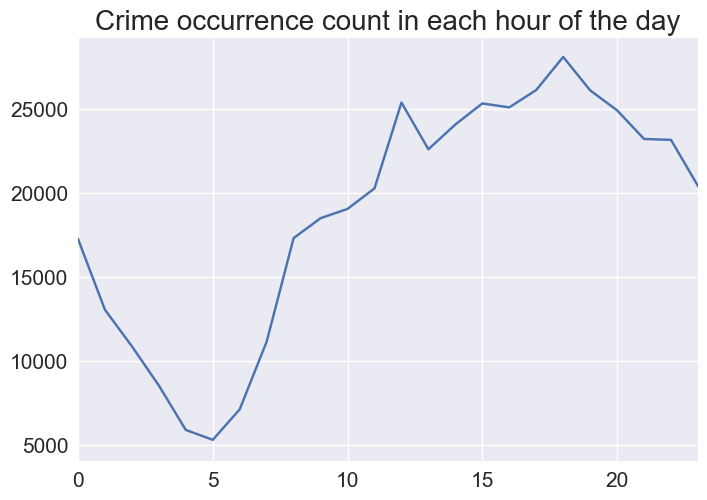

In [17]:
plt.style.use('seaborn-v0_8')

# color = plt.cm.ocean(np.linspace(0, 1, 15))
x = range(24)
y = [cr["TIME"].value_counts()[label] for label in x]
plt.plot(x,y)

plt.title('Crime occurrence count in each hour of the day',fontsize = 20)

plt.yticks(fontsize = 15)
plt.xticks(rotation = 0,fontsize = 15)
plt.xlim(0,23)
plt.ylim(4000)
plt.show()

# 3. 不同特征之间的关系

计算各个有记录案例的持续时间（“ END_DATE ” - “ START_DATE ”，单位为小时）。

In [18]:
cr["REPORT_DELAY_HOURS"] = ''
hour_delay = list()

# 1:end date, 2:start date
def dateDiffInHours(t1, t2):
    td = t1 - t2
    return td.days * 24 + td.seconds/3600 + 1
        
for i in range (len(cr)):
    start = str(cr["START_DATE"].iloc[i])
    end = str(cr["END_DATE"].iloc[i])
    if start[0] == '2' and end[0] == '2':
        y1 = int(''.join(end[0:4]))
        y2 = int(''.join(start[0:4]))
        m1 = int(''.join(end[5:7]))
        m2 = int(''.join(start[5:7]))
        d1 = int(''.join(end[8:10])) 
        d2 = int(''.join(start[8:10]))
        h1 = int(''.join(end[11:13]))
        h2 = int(''.join(start[11:13]))
        mm1 = int(''.join(end[14:16]))
        mm2 = int(''.join(start[14:16]))
        endTime = datetime.datetime(y1,m1,d1,h1,mm1)
        startTime = datetime.datetime(y2,m2,d2,h2,mm2)
        dure = abs(dateDiffInHours(endTime,startTime))
    else:
        dure = -1
    hour_delay.append(dure)
    

cr["REPORT_DELAY_HOURS"] = hour_delay
# cr.DURATION.value_counts()
# max(cr["DURATION"])
# plt.scatter(cr["DURATION"], cr["offensekey"])
# plt.xlim(0,10000)
# plt.show()

根据各可以用数值表示的且不重复的数据绘制热力图。由于部分数据依赖于人为赋值，采用 Pearson chi-方统计并不合适。所以此处采用 Cramér's V 来计算相关性。

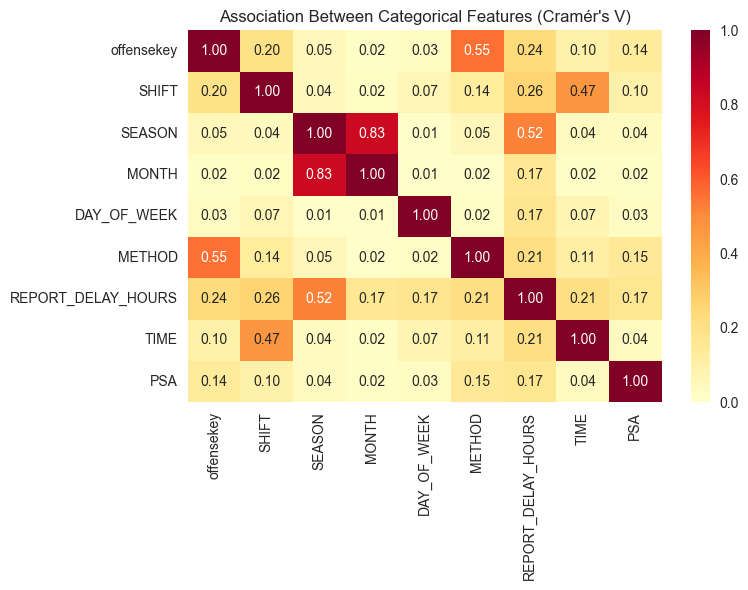

In [19]:
cr = cr.copy()
cr["DAY_OF_WEEK"] = dayOfWeek_abbr
cr["MONTH"] = cr["START_DATE"].astype("string").str.slice(5, 7)

features = ["offensekey", "SHIFT", "SEASON","MONTH","DAY_OF_WEEK", "METHOD","REPORT_DELAY_HOURS","TIME","PSA"]
features = [col for col in features if col in cr.columns]

data = cr[features].copy().fillna("Unknown").astype(str)

def cramers_v(x, y):
    table = pd.crosstab(x, y)

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

# 计算每一对特征的 Cramér's V
association = pd.DataFrame(
    np.eye(len(features)),
    index=features,
    columns=features
)

for i, feature1 in enumerate(features):
    for feature2 in features[i + 1:]:
        value = cramers_v(data[feature1], data[feature2])
        association.loc[feature1, feature2] = value
        association.loc[feature2, feature1] = value

plt.figure(figsize=(8, 6))
sns.heatmap(
    association,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)
plt.title("Association Between Categorical Features (Cramér's V)")
plt.tight_layout()
plt.show()

## 3.1 “ REPORT_DELAY_HOURS ”与“ SEASON/MONTH ”之间的相关性

排除掉显然有因果关系的因素，观察图中显示 REPORT_DELAY_HOURS 和 SEASON 的相关系数有 0.52，但是与同样表示一年中一段时间的 MONTH 仅有 0.17。我们通过画箱线图研究 REPORT_DELAY_HOURS 分别与这两者的关系：

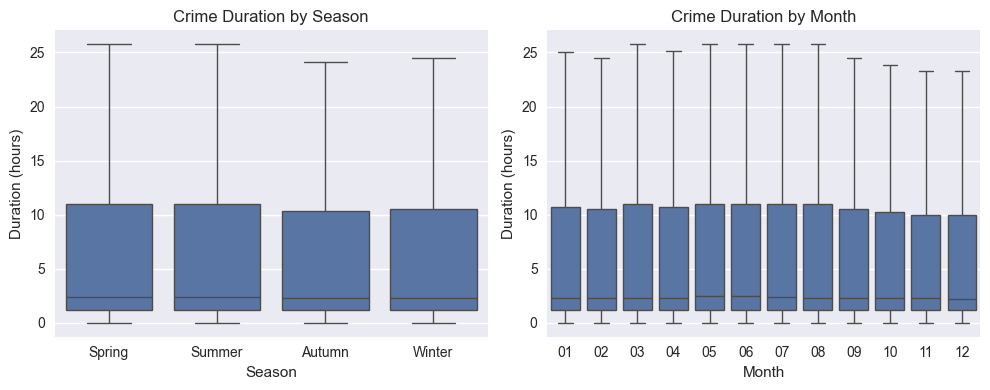

In [20]:
plot_data = cr[["SEASON", "MONTH", "REPORT_DELAY_HOURS"]].copy()

plot_data["REPORT_DELAY_HOURS"] = pd.to_numeric(plot_data["REPORT_DELAY_HOURS"], errors="coerce")
plot_data["MONTH"] = pd.to_numeric(plot_data["MONTH"], errors="coerce")
plot_data["SEASON"] = (
    plot_data["SEASON"]
    .astype("string")
    .str.strip()
    .str.title()
    .replace({"Fall": "Autumn"})
)

plot_data = plot_data.dropna(subset=["SEASON", "MONTH", "REPORT_DELAY_HOURS"])
plot_data = plot_data[plot_data["REPORT_DELAY_HOURS"] >= 0]
plot_data["MONTH"] = plot_data["MONTH"].astype(int).astype(str).str.zfill(2)

# 只绘制数据中实际出现的季节，并按常见顺序排列
preferred_order = ["Spring", "Summer", "Autumn", "Winter"]
present_seasons = plot_data["SEASON"].unique().tolist()
season_order = [s for s in preferred_order if s in present_seasons]
season_order += [s for s in present_seasons if s not in season_order]

month_order = [
    month for month in [f"{m:02d}" for m in range(1, 13)]
    if month in plot_data["MONTH"].unique()
]

fig, axes = plt.subplots(1,2,figsize=(10, 4))

sns.boxplot(
    data=plot_data,
    x="SEASON",
    y="REPORT_DELAY_HOURS",
    order=season_order,
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title("Crime Duration by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Duration (hours)")

sns.boxplot(
    data=plot_data,
    x="MONTH",
    y="REPORT_DELAY_HOURS",
    order=month_order,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Crime Duration by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Duration (hours)")
plt.tight_layout()
plt.show()

热力图初步显示 SEASON 与 REPORT_DELAY_HOURS 的关联值为 0.52，高于 MONTH 与 REPORT_DELAY_HOURS 的 0.17；但箱线图中各季节、月份的中位数和分布整体相近，没有明显差异。因此，目前没有清楚的描述性证据表明案件持续时间存在明显的季节或月度变化。

## 3.2 “ SHIFT ”与“ offensekey ”之间的相关性

在热力图中，SHIFT 与 offensekey 两者的相关系数约为 0.2 。直觉和生活常识告诉我们，“月黑风高杀人夜”，即作案时间和犯罪类型是有关的。我们研究这两者的关系。

In [21]:
# 对每个轮班中发生的总犯罪数量进行统计
shift_offensekey = pd.crosstab(
    cr["offensekey"],
    cr["SHIFT"],
    normalize="index"
).mul(100).round(1)

shift_offensekey = shift_offensekey.rename(
    columns={0: "day", 1: "night", 2: "midnight"}
)

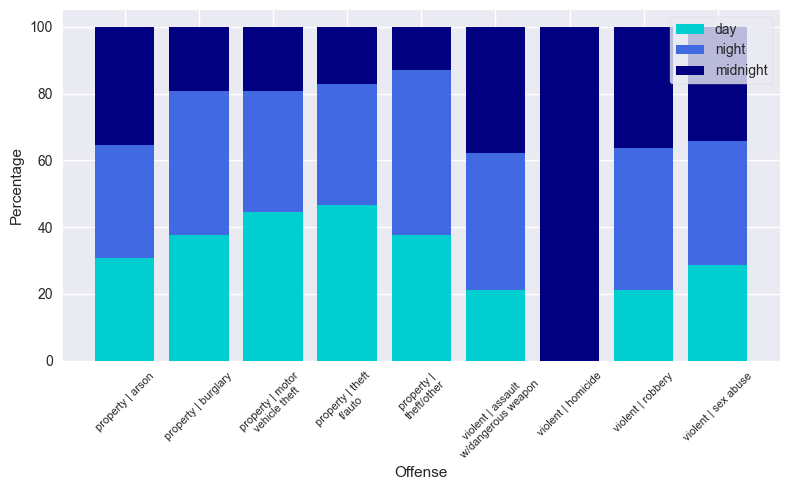

In [22]:
x = range(len(shift_offensekey))

labels = [
    fill(str(label).replace("|", " | "), width=20, break_long_words=False)
    for label in shift_offensekey.index
]

plt.figure(figsize=(8, 5))
plt.style.use("seaborn-v0_8")

plt.bar(x, shift_offensekey["day"], label="day", color="darkturquoise")
plt.bar(
    x,
    shift_offensekey["night"],
    bottom=shift_offensekey["day"],
    label="night",
    color="royalblue"
)
plt.bar(
    x,
    shift_offensekey["midnight"],
    bottom=shift_offensekey["day"] + shift_offensekey["night"],
    label="midnight",
    color="navy"
)

plt.xticks(x, labels, rotation=45, fontsize=8)
plt.xlabel("Offense")
plt.ylabel("Percentage")
plt.legend(frameon = True)
plt.tight_layout()
plt.show()

通过柱状图可以迅速发现，凶杀案（ homicide ）均在第三班即深夜轮班（ midnight shift ）发生。

有关财产的案件中，与盗窃相关的案件，如入室盗窃（ burglary ）、机动车盗窃（ motor vehicle theft ）以及另外两类盗窃都是主要发生在日班与夜班，而深夜轮班发生较少；而纵火案（ arson ）在深夜轮班时发生比例增加，三个轮班中的纵火案案件数量基本持平。

而与暴力相关的案件，均主要在夜间，即夜班（ night shift ）和深夜轮班（ midnight shift ）中发生，其中凶杀案（ homicide ）仅在深夜轮班发生。在暴力案件中，除了凶杀案仅在深夜轮班发生之外，其他均是在夜班中案件发生最多。其中性虐待（ sex abuse ）在日班中发生也较多。

这些模式可能与犯罪发生环境、人员活动规律或案件记录方式有关。例如，白天住宅可能较少有人在家，这或许与部分入室盗窃案件的分布有关；午夜的低人流或较低可见度也可能是值得进一步检验的解释。但现有数据不能确认这些原因。凶杀案在午夜符合“月黑风高杀人夜”这一说法，晚上作案不容易被发现。而性虐待在白天发生较多，与人们通常认为这一类事件常发生在夜里相比更反直觉。不能仅凭常见印象推断案件发生时段。其分布还可能受案件发现和记录时间影响。

为进一步考察入室盗窃在一周内的分布，下面比较各星期的每日案件数量。

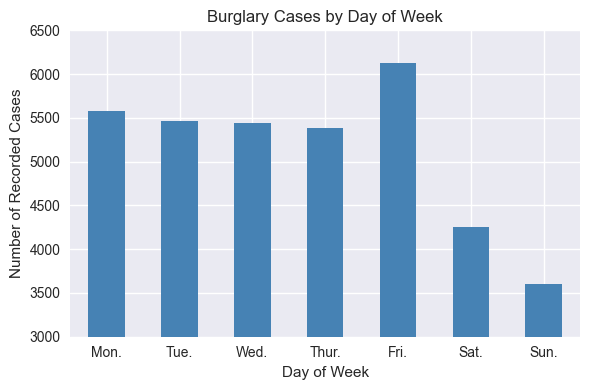

In [23]:
weekday_order = ["Mon.", "Tue.", "Wed.", "Thur.", "Fri.", "Sat.", "Sun."]

burglary = cr[
    cr["offensekey"].astype("string").str.contains(
        "burglary", case=False, na=False
    )
]

weekday_counts = (
    burglary["DAY_OF_WEEK"]
    .value_counts()
    .reindex(weekday_order, fill_value=0)
)

plt.figure(figsize=(6, 4))
weekday_counts.plot(kind="bar", color="steelblue")

plt.ylim(3000, 6500)
plt.title("Burglary Cases by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Recorded Cases")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

样本期内，平均每个周五记录的入室盗窃最多，工作日的日均记录数整体高于周末。
这与“工作日住宅可能较少有人在家”的猜测相符。

由此，会自然联想到：入室盗窃是否更多发生在有钱人家中？入室盗窃发生概率是否与房价相关？还是说，富人区的警察更负责任，所以会有更少的案件发生？在对数据之间的相关性比较完毕后，我们将在下一节对这个问题展开讨论。

## 3.3 “offensekey”与“PSA”之间的关系

从热力图中发现，offensekey 与 PSA 的相关系数高达 0.25，两者之间可能有较弱的联系。运用与上面相同的办法，画出 offensekey 与 PSA的折线图。

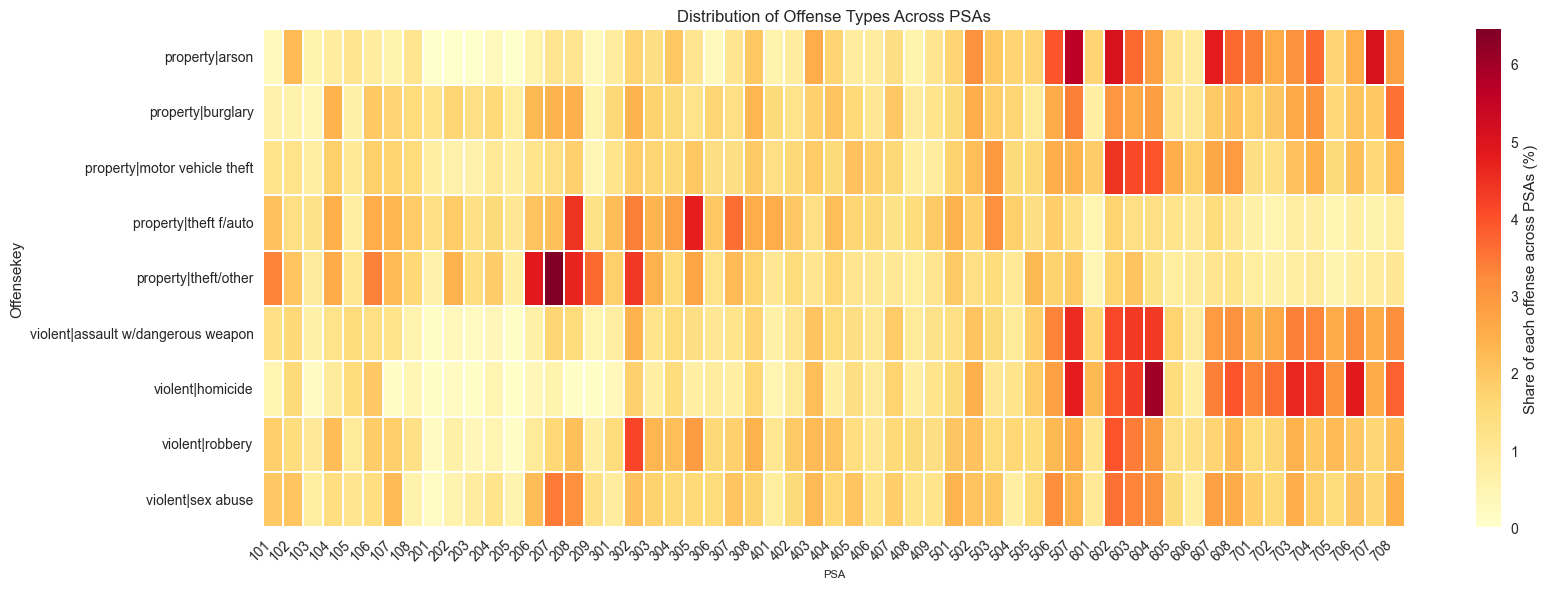

In [24]:
# #cr_offense_PSA = cr[["offensekey","PSA"]]
# offense_PSA = pd.DataFrame(columns = (cr.offensekey.value_counts().sort_index().index))
# heat_data = offense_PSA.T.sort_index(axis=1)

offense_PSA = pd.crosstab(
    cr["PSA"],
    cr["offensekey"],
    normalize="columns"
).mul(100)

heat_data = offense_PSA.T.sort_index(axis=1)

heat_data.columns = pd.to_numeric(heat_data.columns).astype(int).astype(str)
plt.figure(figsize=(max(10, heat_data.shape[1] * 0.3), 6))
ax = sns.heatmap(
    heat_data,
    cmap="YlOrRd",
    linewidths=0.2,
    cbar_kws={"label": "Share of each offense across PSAs (%)"}
)

ax.set_title("Distribution of Offense Types Across PSAs")
ax.set_xlabel("PSA",fontsize=8)
ax.set_ylabel("Offensekey")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

盗窃在 PSA 为 206-209 的范围内占比特别高，而凶杀和纵火则在 507，602-604，607-708占比较高。

# 4 根据地理位置对犯罪地点进行 kNN 分类

本届将对犯罪地点以经纬度为特征进行 kNN 分类，作为 kNN 算法的一个应用。此处将：

1. 随机切分地图，分别作为训练集和测试集；
2. 按地图区域留出一部分作为测试集，来验证模型能否推广到更远的地点。

## 4.1 随机切分地图，分别作为训练集和测试集

In [25]:
# 提取可用的数据：经纬度以及CLUSTER的编号
cr_location = cr[
    ["LONGITUDE", "LATITUDE", "NEIGHBORHOOD_CLUSTER"]
].dropna().copy()
cr_location_minmax = pd.DataFrame()

# 数据 min-max 标准化
def min_max_normalize(x):
    return (x - x.min())/(x.max() - x.min())

cr_location_minmax = cr_location[["LONGITUDE", "LATITUDE"]].apply(min_max_normalize)

X = cr_location[["LONGITUDE", "LATITUDE"]]
y = cr_location["NEIGHBORHOOD_CLUSTER"]

X = cr_location_minmax
cr_train, cr_test,\
cr_train_labels, cr_test_labels \
= model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [26]:
knn_model = KNeighborsClassifier(n_neighbors = 20)
knn_model.fit(cr_train, cr_train_labels)
print("KNN training complete")

KNN training complete


In [27]:


# 用训练好的模型预测测试集
cr_test_pred = knn_model.predict(cr_test)

# 整体准确率
print("Test accuracy:", accuracy_score(cr_test_labels, cr_test_pred))

# 每个 cluster 的 precision、recall、F1 和样本数
print(classification_report(
    cr_test_labels,
    cr_test_pred,
    zero_division=0
))

# 混淆矩阵
print(confusion_matrix(cr_test_labels, cr_test_pred))

Test accuracy: 0.9931867660827289
              precision    recall  f1-score   support

         1.0       0.99      0.99      0.99      2172
         2.0       1.00      1.00      1.00      7169
         3.0       0.99      0.99      0.99      3863
         4.0       1.00      1.00      1.00      2606
         5.0       0.99      1.00      0.99      1395
         6.0       0.99      0.99      0.99      5038
         7.0       0.99      0.99      0.99      3031
         8.0       0.99      1.00      1.00      5986
         9.0       0.99      1.00      0.99      1551
        10.0       1.00      1.00      1.00       768
        11.0       1.00      0.99      1.00      1539
        12.0       0.99      1.00      1.00       561
        13.0       0.99      1.00      0.99       621
        14.0       0.98      0.99      0.98       747
        15.0       1.00      0.98      0.99      1026
        16.0       0.98      1.00      0.99       506
        17.0       1.00      0.99      0.99    

## 4.2 按地图区域留出一部分作为测试集

在这个分类中，选择东北角作为测试集。

In [28]:
lon_mid = X["LONGITUDE"].median()
lat_mid = X["LATITUDE"].median()

test_mask = (
    (X["LONGITUDE"] >= lon_mid) &
    (X["LATITUDE"] >= lat_mid)
)

X_train_spatial = X.loc[~test_mask]
X_test_spatial = X.loc[test_mask]
y_train_spatial = y.loc[~test_mask]
y_test_spatial = y.loc[test_mask]

scaler = MinMaxScaler()
X_train_spatial_scaled = scaler.fit_transform(X_train_spatial)
X_test_spatial_scaled = scaler.transform(X_test_spatial)

knn_spatial = KNeighborsClassifier(n_neighbors=20)
knn_spatial.fit(X_train_spatial_scaled, y_train_spatial)

y_pred_spatial = knn_spatial.predict(X_test_spatial_scaled)

print("Spatial accuracy: ",
      accuracy_score(y_test_spatial, y_pred_spatial))
print(classification_report(
    y_test_spatial, y_pred_spatial, zero_division=0
))

Spatial accuracy:  0.3706310430831255
              precision    recall  f1-score   support

         3.0       0.14      0.62      0.22       111
         8.0       0.06      1.00      0.11        64
        17.0       0.30      0.85      0.44      1275
        18.0       0.09      0.76      0.15       472
        19.0       0.38      0.16      0.23      6132
        20.0       0.00      0.00      0.00      5333
        21.0       0.67      0.70      0.69     13534
        22.0       0.00      0.00      0.00     14864
        23.0       0.27      0.92      0.42      7134
        24.0       0.00      0.00      0.00      6049
        25.0       0.40      0.97      0.57      1251
        29.0       0.99      0.54      0.70      1018
        30.0       0.00      0.00      0.00         0
        31.0       0.73      1.00      0.84      1298
        46.0       0.00      0.00      0.00         3

    accuracy                           0.37     58538
   macro avg       0.27      0.50      0.2

可见，如果仅依靠经纬度，kNN 并不适合空间划分。随机测试分数不能代表它对新区域的泛化能力。

在这里，我们将 95% 用来训练模型，5% 用来测试模型（因为电脑内存不够）。由于只要求用地理位置进行聚类，删去其他与地理位置无关的信息、以及不方便处理的信息，并且将其 min-max 标准化，删去缺失值。

In [29]:
y = cr_location['NEIGHBORHOOD_CLUSTER']
del cr_location['NEIGHBORHOOD_CLUSTER']
X = cr_location_minmax
cr_train, cr_test,\
cr_train_labels, cr_test_labels \
= model_selection.train_test_split(X, y, test_size=0.05, random_state=0)

## 4.3 模型性能提升

此处进行对 k 取不同的值来对实现模型进行性能的提升。我们将测试k = 1, 5, 10, 20, 50, 80, 100时的结果。由于输出标签类型较多，此处将仅通过准确率来判断模型的性能。

In [30]:
k_list = [1, 5, 10, 20, 50, 80, 100]

# 每组依次放：切分名称、训练特征、测试特征、训练标签、测试标签
splits = [
    ("Randomly", cr_train, cr_test, cr_train_labels, cr_test_labels),
    ("Spatially", X_train_spatial_scaled, X_test_spatial_scaled,
     y_train_spatial, y_test_spatial)
]

rows = []

for name, Xtr, Xte, ytr, yte in splits:
    for k in k_list:
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        accuracy = metrics.accuracy_score(yte, pred)
        rows.append({
            "Method of Selection": name,
            "k": k,
            "Accuracy": accuracy
        })

result = pd.DataFrame(rows)
result["Accuracy"] = (result["Accuracy"] * 100).round(2).astype(str) + "%"

result.pivot(index="k", columns="Method of Selection", values="Accuracy")

Method of Selection,Randomly,Spatially
k,,
1,99.34%,38.12%
5,99.55%,37.1%
10,99.46%,37.06%
20,99.39%,37.06%
50,99.15%,37.09%
80,98.89%,36.61%
100,98.8%,35.61%


对于随机切分，最优的选择大概是 5 左右。然而对于空间切分，最优的选择则是 1。

# 5. 犯罪与地点和房价的关系

## 5.1 预处理

In [31]:
pr = pd.read_csv('DC_Properties.csv')

C:\Users\ASUS\AppData\Local\Temp\ipykernel_185124\1361234038.py:1: DtypeWarning: Columns (18,19,20,21,22,23,24,33,34,35,37,43,45) have mixed types. Specify dtype option on import or set low_memory=False.
  pr = pd.read_csv('DC_Properties.csv')


查找离群值：

<Axes: xlabel='PRICE'>

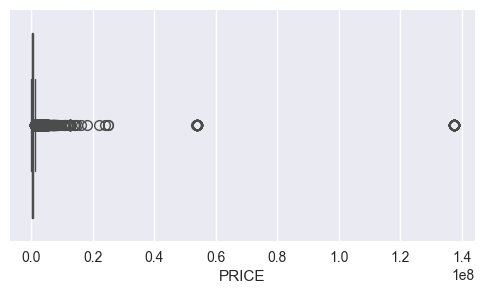

In [32]:
prices = pr.PRICE;
#print(prices.describe())
fig, ax = plt.subplots(figsize=(6, 3))
sns.boxplot(x=prices)

离群值过大，房价的差距体现在数量级。考虑 $\log$。下图中 $x$ 轴为房子在列表中的编号， $y$ 轴为房价数量级：

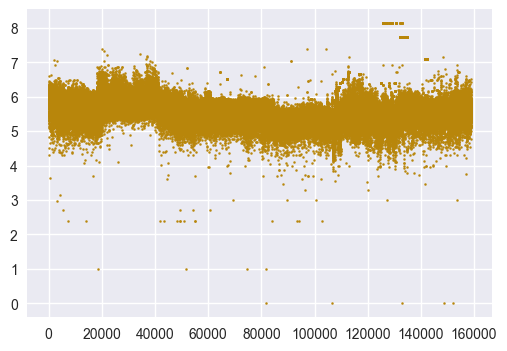

In [33]:
pr_noln = pr.copy()                                            # 原本房价的副本（no ln，未取对数）
PRICE = pr["PRICE"]

prices = prices.values.tolist()
PRICE_LOG10 = np.log10(prices)
    
x = range(len(PRICE_LOG10))
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(x,PRICE_LOG10,color = 'darkgoldenrod',s = 2)
plt.show();

## 5.2 房价/犯罪/街区之间的关系

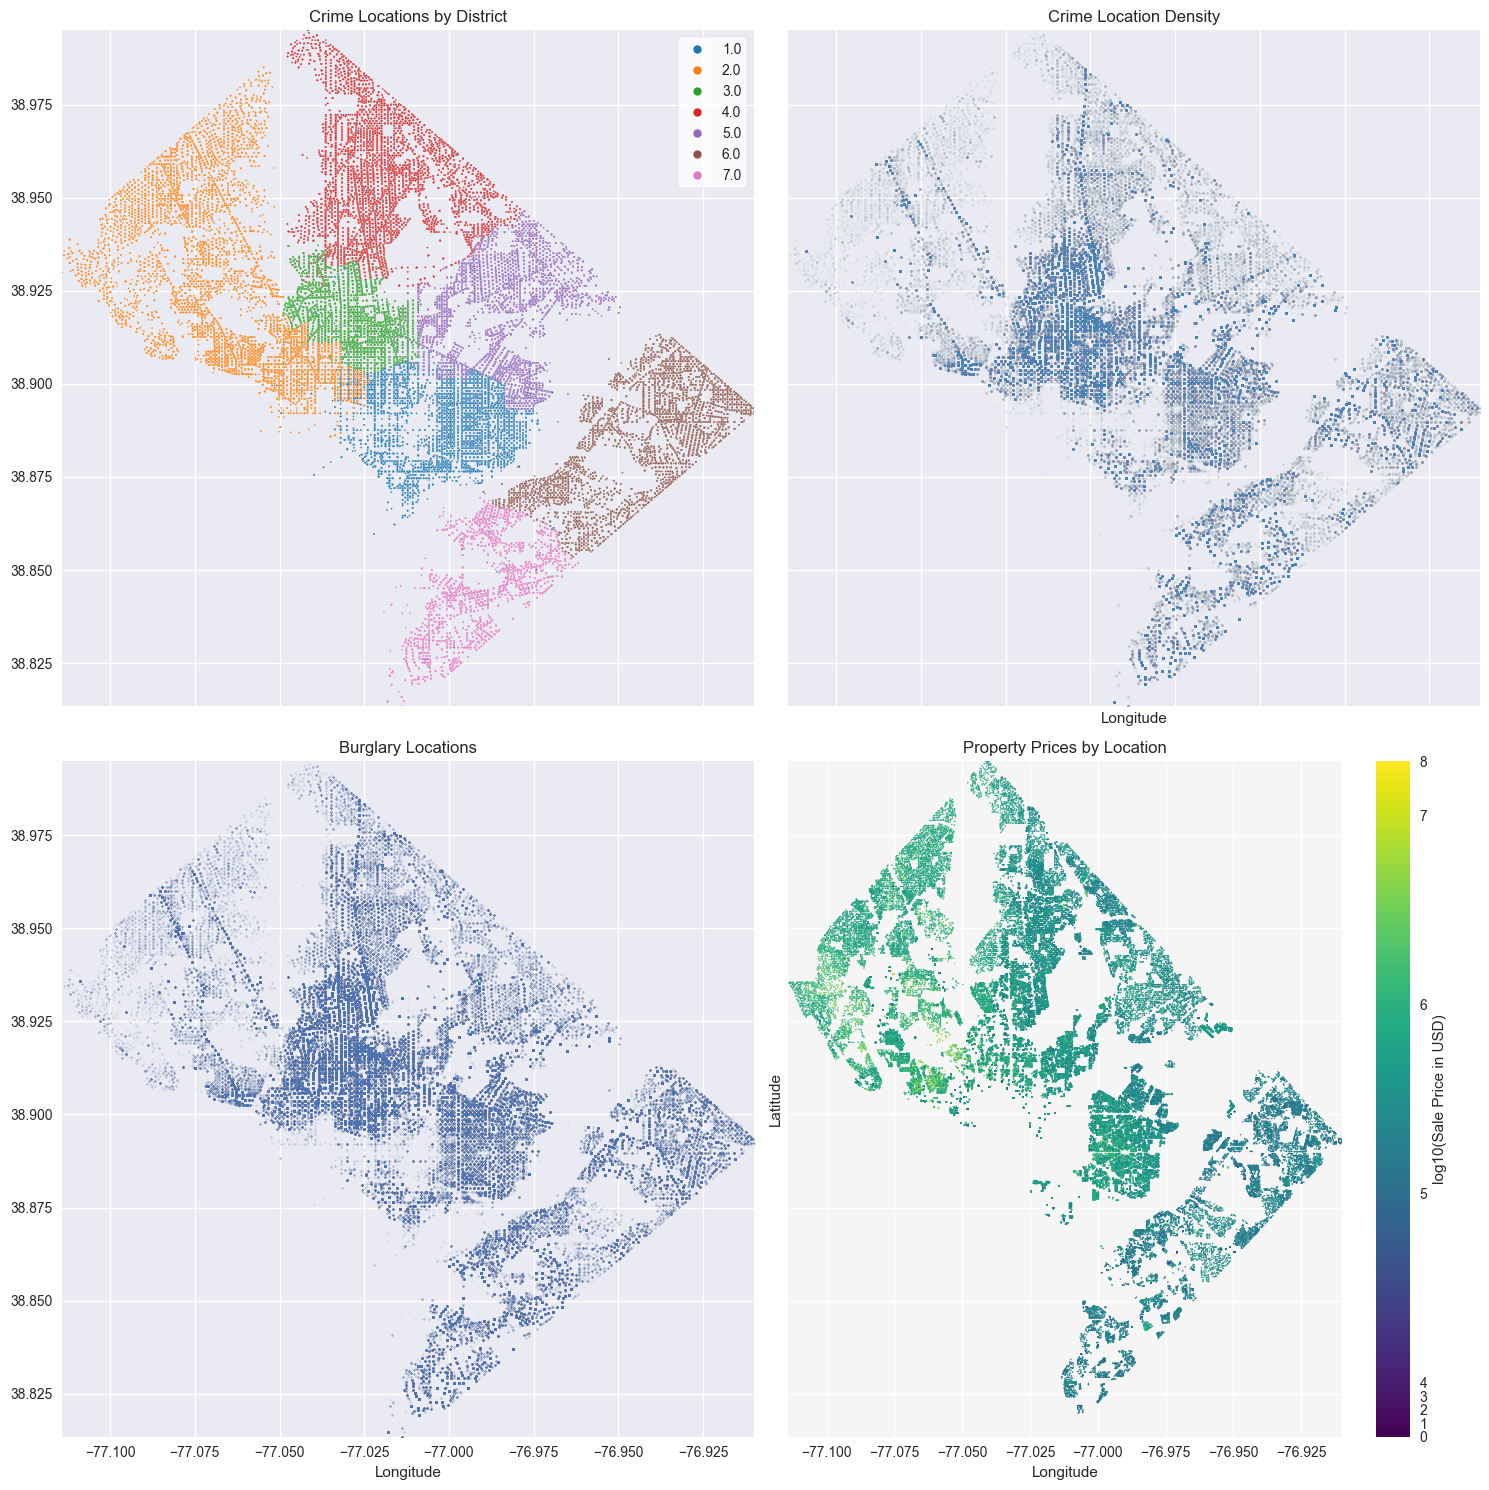

In [34]:
crime_plot_data = cr.dropna(
    subset=["LONGITUDE", "LATITUDE", "DISTRICT"]
).copy()

price_plot_data = pr_noln.copy()
price_plot_data["PRICE_LOG10"] = PRICE_LOG10
price_plot_data = price_plot_data.dropna(
    subset=["LONGITUDE", "LATITUDE", "PRICE_LOG10"]
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 15),
    sharex=True,
    sharey=True
)

price_data = pr.loc[
    pr["PRICE"].notna() & (pr["PRICE"] > 0)
].copy()

price_data["PRICE_LN"] = np.log10(price_data["PRICE"])


# 左上图：按 District 着色的犯罪位置
sns.scatterplot(
    data=crime_plot_data,
    x="LONGITUDE",
    y="LATITUDE",
    hue="DISTRICT",
    palette="tab10",
    s=1.5,
    alpha=1,
    ax=axes[0,0]
)
axes[0,0].legend(frameon=True, facecolor='white', markerscale=5)
axes[0,0].set_title("Crime Locations by District")
axes[0,0].set_xlabel("Longitude")
axes[0,0].set_ylabel("")


# 右上：用透明度显示犯罪点位密度
# axes[0,1].set_facecolor("#f5f5f5")
axes[0,1].scatter(
    crime_plot_data["LONGITUDE"],
    crime_plot_data["LATITUDE"],
    color="steelblue",
    s=1.5,
    alpha=0.02
)
axes[0,1].set_title("Crime Location Density")
axes[0,1].set_xlabel("Longitude")
axes[0,1].set_ylabel("")



# 左下：入室盗窃点位密度
burglary_code = "property|burglary"  # 填入 burglary 对应的 offensekey 编号
burglary_data = cr.loc[cr["offensekey"] == burglary_code].dropna(
    subset=["LONGITUDE", "LATITUDE"]
)
axes[1,0].scatter(
    crime_plot_data["LONGITUDE"],
    crime_plot_data["LATITUDE"],
    #color="yellow",
    s=1.5,
    alpha=0.05,
)
axes[1,0].set_title("Burglary Locations")
axes[1,0].set_xlabel("Longitude")
axes[1,0].set_ylabel("")

# 右下图：
forward = lambda x: np.interp(x, [0, 4, 7, 8], [0, 0.08, 0.92, 1])
inverse = lambda x: np.interp(x, [0, 0.08, 0.92, 1], [0, 4, 7, 8])
price_norm = FuncNorm((forward, inverse), vmin=0, vmax=8, clip=True)

axes[1,1].set_facecolor("#f5f5f5")
price_points = axes[1,1].scatter(
    price_plot_data["LONGITUDE"],
    price_plot_data["LATITUDE"],
    c=price_plot_data["PRICE_LOG10"],
    cmap="viridis",
    norm=price_norm,
    s=0.5,
    alpha=1
)
axes[1,1].set_title("Property Prices by Location")
axes[1,1].set_xlabel("Longitude")
axes[1,1].set_ylabel("Latitude")


fig.colorbar(
    price_points,
    ax=axes[1,1],
    ticks=range(9),
    label="log10(Sale Price in USD)"
)

# 三张图统一经纬度范围，便于并排比较
all_lon = pd.concat([crime_plot_data["LONGITUDE"], crime_plot_data["LONGITUDE"]])
all_lat = pd.concat([crime_plot_data["LATITUDE"], crime_plot_data["LATITUDE"]])

for ax in axes.ravel():
    ax.set_xlim(all_lon.min(), all_lon.max())
    ax.set_ylim(all_lat.min(), all_lat.max())

plt.tight_layout()
plt.show()

通过对比得到如下粗略结论：

1. 高房价大多分布在 2 号、3 号街区，低房价大多分布在 7 号街区；
2. 犯罪行为在 3 号街区附近密度较高，而在边缘分布较少；
3. 入室盗窃行为在高房价区域和低房价区域密度类似，并且在道路旁边的住宅中更易发生。

## 6 对房价估算的建模

## 6.1 预处理

In [35]:
price_data = pr.loc[
    pr["PRICE"].notna() &
    (pr["PRICE"] > 0) &
    pr["SALEDATE"].notna()
].copy()

In [36]:
# 对于可以量化的指标，将其转换为数字。空调有/无为二元变量，转换为0和1：
pr["AC"] = (
    pr["AC"]
    .astype("string")
    .str.strip()
    .str.upper()
    .map({"Y": 1, "N": 0})
)

In [37]:
# 房间评级可以转换为分数：
grade_order = [
    "Low Quality",
    "Fair Quality",
    "Average",
    "Above Average",
    "Good Quality",
    "Very Good",
    "Excellent",
    "Superior",
    "Exceptional-A",
    "Exceptional-B",
    "Exceptional-C",
    "Exceptional-D"
]

grade_map = {grade: rank for rank, grade in enumerate(grade_order, start=1)}

pr["GRADE_CODE"] = pr["GRADE"].map(grade_map)
pr["PRICE_LOG10"] = PRICE_LOG10

In [38]:
# 提取售出年份
pr["SALE_YEAR"] = pd.to_datetime(
    pr["SALEDATE"], errors="coerce"
).dt.year

In [39]:
pd.to_datetime(pr["SALEDATE"], errors="coerce").dt.year.value_counts().sort_index()

SALEDATE
1947.0        1
1949.0        1
1950.0        1
1955.0        2
1956.0        1
          ...  
2014.0     8635
2015.0     9578
2016.0    10491
2017.0    12399
2018.0     6636
Name: count, Length: 65, dtype: int64

另一值得关注的与房价有关的信息是地段。在原房价表格中，给出了 WARD （华盛顿特区的行政选区）、ZIPCODE （邮政编码）、NATIONALGRID （国家网格坐标）、CENSUS_TRACT/BLOCK （普查区域）、FULLADRESS （地址）以及经纬度。同时，还可以根据刚才的 kNN 模型来分出 CLUSTER。其中，NATINOALGRID 显然和经纬度有重复所以不考虑。

此处，我们将比较 WARD 和 CLUSTER 的预测准确度。

In [40]:
# 房产经纬度转成数值；无法转换的值会变成 NaN
house_xy = pr[["LONGITUDE", "LATITUDE"]].apply(
    pd.to_numeric, errors="coerce"
)
valid = house_xy.notna().all(axis=1)

# 使用犯罪数据的最小值、最大值缩放，和训练 KNN 时保持一致
crime_xy = cr_location[["LONGITUDE", "LATITUDE"]]
house_scaled = (
    house_xy.loc[valid] - crime_xy.min()
) / (
    crime_xy.max() - crime_xy.min()
)

# 用已有模型预测，并写回房价表
pr["KNN_CLUSTER"] = pd.NA
pr.loc[valid, "KNN_CLUSTER"] = knn_model.predict(house_scaled)

#print(pr["KNN_CLUSTER"].value_counts(dropna=False).sort_index())

## 6.2 特征选择

本研究分别计算 Pearson 相关系数和 Spearman 秩相关系数，并以相同阈值筛选数值特征。两种方法得到的候选特征集合一致，因此正文仅展示 Pearson 相关结果；Spearman 分析作为一致性检查，不再重复呈现。

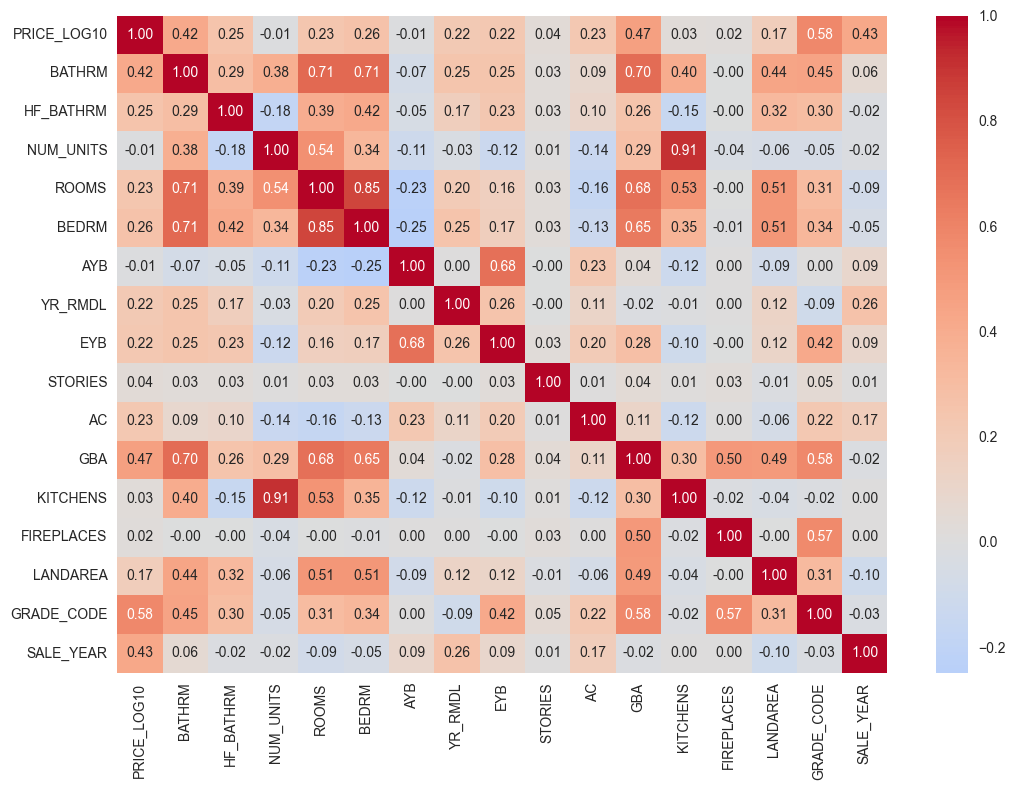

In [41]:
# 将一些数据 min-max 标准化，然后选择数据画热力图

numeric_cols = [
    "PRICE_LOG10","BATHRM", "HF_BATHRM", "NUM_UNITS", "ROOMS",
    "BEDRM", "AYB", "YR_RMDL", "EYB", "STORIES","AC",
    "GBA", "KITCHENS", "FIREPLACES", "LANDAREA","GRADE_CODE","SALE_YEAR"
]

corr_data = pr[numeric_cols].dropna(subset=["PRICE_LOG10"])
corr_pearson = corr_data.corr(method="pearson")

plt.figure(figsize=(11, 8))
sns.heatmap(corr_pearson, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.tight_layout()
plt.show()

对于想分析的类别变量，进行 Cramér's V 分析

In [42]:
# categorical columns
cat_cols = [
    "HEAT", "STYLE", "KNN_CLUSTER","AC",
    "STRUCT", "CNDTN", "EXTWALL", "ROOF", "INTWALL",
    "WARD", "ASSESSMENT_NBHD"
]

# 只保留 pr 中实际存在的列
#cat_cols = [col for col in cat_cols if col in pr.columns]

data = pr[cat_cols + ["PRICE_LOG10"]].copy()

# 统一类别格式；把 "No Data" 当成缺失值
for col in cat_cols:
    data[col] = data[col].astype("string").str.strip()
    data[col] = data[col].replace({"No Data": pd.NA, "": pd.NA})

# 按 log10 房价切成四档：最低 25% 到最高 25%
price_bin = pd.qcut(
    data["PRICE_LOG10"],
    q=4,
    labels=False,
    duplicates="drop"
)

bin_names = ["Low", "Mid-low", "Mid-high", "High"]
data["PRICE_LEVEL"] = price_bin.map(dict(enumerate(bin_names))).astype("string")

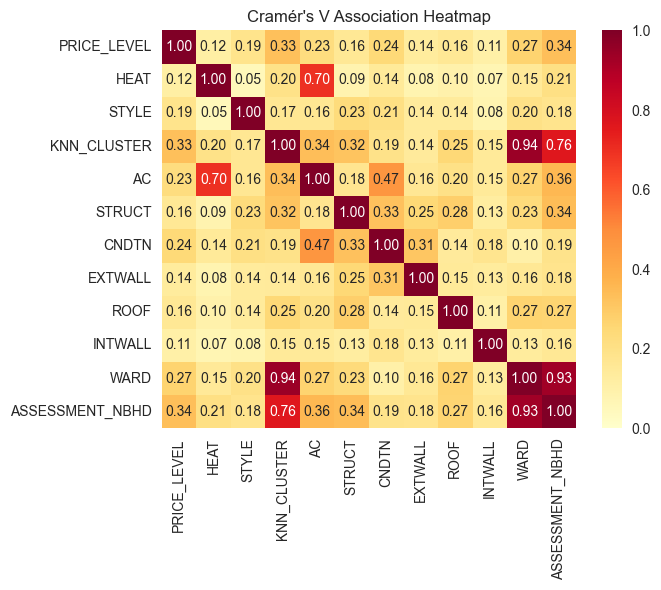

In [43]:
# Cramér's V
def cramers_v(x, y):
    valid = pd.DataFrame({"x": x, "y": y}).dropna()
    table = pd.crosstab(valid["x"], valid["y"])

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()

    return np.sqrt(
        chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1))
    )

# 计算各类别变量与价格档位之间，以及彼此之间的关联
features = ["PRICE_LEVEL"] + cat_cols
association = pd.DataFrame(
    np.eye(len(features)),
    index=features,
    columns=features
)

for i, col1 in enumerate(features):
    for col2 in features[i + 1:]:
        value = cramers_v(data[col1], data[col2])
        association.loc[col1, col2] = value
        association.loc[col2, col1] = value

# 绘图
plt.figure(figsize=(7, 6))
sns.heatmap(
    association,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)
plt.title("Cramér's V Association Heatmap")
plt.tight_layout()
plt.show()

In [44]:
# 对于 Spearman，提取绝对值 >=0.4 的作为特征。对于 Cramér's V，提取 >=0.3 作为特征：

selected_numerical_cols = corr_pearson.columns[(abs(corr_pearson.iloc[0]) >= 0.4) &
    (corr_pearson.columns != "PRICE_LOG10")].tolist()
selected_cat_cols = association.columns[(association.iloc[0] >= 0.3) &
    (association.columns != "PRICE_LEVEL")].tolist()

print(selected_numerical_cols)
print(selected_cat_cols)

['BATHRM', 'GBA', 'GRADE_CODE', 'SALE_YEAR']
['KNN_CLUSTER', 'ASSESSMENT_NBHD']


需要注意的是，虽然 BATHRM （浴室数量）和 PRICE_LOG10 承线性相关，却和 PRICE 看起来线性无关。可能是因为两者数量级差距导致的。我们对于是否考虑 BATHRM 两种情况对比莫模型。

kNN_CLUSTER入选了备用的特征。由于 kNN_CLUSTER 的数据来源于刚才的模型，我们好奇，同样作为描述地段的 WARD 与之相比表现如何。

In [45]:
selected_cat_cols_ward = ["WARD"] + [
    col for col in selected_cat_cols
    if col != "KNN_CLUSTER"
]

本研究的预测目标是房屋的总成交价，而不是单位面积房价。建筑面积（GBA）已作为模型特征之一，模型同时使用线性回归和残差随机森林，以拟合建筑面积与总房价之间可能存在的线性及非线性关系。因此，针对本研究的总价预测目标，无需再将成交价除以建筑面积，另行构造单位面积房价作为目标。

## 6.3 模型建立

对于 selected_cat_cols 以及 selected_cat_cols_ward 中的特征，适合使用随机森林回归；而对于 selected_numerical_cols 中的特征，适合使用线性回归。选择时间较早（2013年及以前）的交易作为训练集，时间稍晚（2014和2015年）的交易作为验证集，时间更晚（2017和2018年）的交易作为测试集。

以 MAE（Mean Absolute Value, 平均绝对误差）来评测模型的优劣。

In [46]:
# 按照 8:1:1 的比例划分训练集、验证集、测试集

price_data = pr.loc[
    pr["PRICE"].notna()
    & (pr["PRICE"] > 0)
    & pr["SALE_YEAR"].notna()
].copy()

price_data = price_data.sort_values("SALEDATE").reset_index(drop=True)

n = len(price_data)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

train_data = price_data.iloc[:train_end].copy()
val_data = price_data.iloc[train_end:val_end].copy()
test_data = price_data.iloc[val_end:].copy()

for name, data in [
    ("Training set", train_data),
    ("Validating set", val_data),
    ("Testing set", test_data)
]:
    print(
        name,":", len(data),
        "(",data["SALE_YEAR"].min(),
        "to",
        data["SALE_YEAR"].max(),")"
    )

Training set : 78572 ( 1982.0 to 2016.0 )
Validating set : 9821 ( 2016.0 to 2017.0 )
Testing set : 9822 ( 2017.0 to 2018.0 )


In [47]:
# 建立模型：先用线性回归、再用随机森林拟合残差
def fit_residual_model(categorical_features, n_trees):
    num_cols = list(dict.fromkeys(
        selected_numerical_cols + ["BATHRM", "SALE_YEAR"]
    ))
    target_cols = {"PRICE", "PRICE_LOG10", "PRICE_LEVEL"}

    num_cols = [c for c in num_cols if c not in target_cols]
    cat_cols = [c for c in categorical_features if c not in target_cols]
    features = num_cols + cat_cols

    fit_data = train_data.sort_values("SALEDATE").reset_index(drop=True)
    X_fit = fit_data[features]
    y_fit = fit_data["PRICE_LOG10"]

    preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="ignore")
        ), cat_cols)
    ])

    # 生成线性回归的样本外预测
    oof_pred = np.full(len(X_fit), np.nan)

    for fit_idx, holdout_idx in TimeSeriesSplit(n_splits=5).split(X_fit):
        linear_fold = make_pipeline(
            clone(preprocessor),
            LinearRegression()
        )
        linear_fold.fit(X_fit.iloc[fit_idx], y_fit.iloc[fit_idx])
        oof_pred[holdout_idx] = linear_fold.predict(X_fit.iloc[holdout_idx])

    # 随机森林学习线性回归的残差
    valid = ~np.isnan(oof_pred)
    residuals = y_fit.iloc[valid].to_numpy() - oof_pred[valid]

    residual_model = make_pipeline(
        clone(preprocessor),
        RandomForestRegressor(
            n_estimators=n_trees,
            random_state=42,
            n_jobs=-1
        )
    )
    residual_model.fit(X_fit.iloc[valid], residuals)

    # 线性回归使用全部训练集拟合
    linear_model = make_pipeline(
        clone(preprocessor),
        LinearRegression()
    )
    linear_model.fit(X_fit, y_fit)

    return linear_model, residual_model, features

In [48]:
def evaluate_residual_model(linear_model, residual_model, features, data):
    X = data[features]
    y_log10 = data["PRICE_LOG10"]

    pred_log10 = (
        linear_model.predict(X)
        + residual_model.predict(X)
    )

    results = data.copy()
    results["ACTUAL_PRICE"] = 10 ** y_log10.to_numpy()
    results["PREDICTED_PRICE"] = 10 ** pred_log10
    results["ERROR"] = (
        results["PREDICTED_PRICE"] - results["ACTUAL_PRICE"]
    )
    results["ABS_ERROR"] = results["ERROR"].abs()
    results["APE"] = (
        results["ABS_ERROR"] / results["ACTUAL_PRICE"] * 100
    )

    mae = mean_absolute_error(
        results["ACTUAL_PRICE"],
        results["PREDICTED_PRICE"]
    )

    return results, mae

In [49]:
rows = []

for cat_name, cat_features in [
    ("selected_cat_cols", selected_cat_cols),
    ("selected_cat_cols_ward", selected_cat_cols_ward)
]:
    for n_trees in [50, 100, 200, 400]:
        linear_model, residual_model, features = fit_residual_model(
            cat_features, n_trees
        )

        _, mae = evaluate_residual_model(
            linear_model, residual_model, features, val_data
        )

        rows.append({
            "CATEGORICAL FEATURE SET": cat_name,
            "NUMBER OF TREES": n_trees,
            "MAE OF VALIDATION SET (DOLLARS)": mae
        })

result_table = pd.DataFrame(rows).pivot(
    index="NUMBER OF TREES",
    columns="CATEGORICAL FEATURE SET",
    values="MAE OF VALIDATION SET (DOLLARS)"
).round(0)

display(result_table)

CATEGORICAL FEATURE SET,selected_cat_cols,selected_cat_cols_ward
NUMBER OF TREES,,
50,229412.0,230523.0
100,229055.0,229999.0
200,229058.0,230086.0
400,228776.0,229959.0


selected_cat_cols 的一组有略微优势。这是可预见的，因为 CLUSTER 分类中将整个特区分为 40 余个小地区，而 WARD 则只分了数十类。除此之外，误差随数的数量增加而稍微减少，从 50 到 400 只有约 0.28% 的变化。考虑到电脑性能和运行所需时间，取用 100。

选取以 CLUSTER 分类的 selected_cat_cols，树数取 100。进行测试：

In [50]:
linear_model, residual_model, features = fit_residual_model(selected_cat_cols, 100)

test_errors, test_mae = evaluate_residual_model(linear_model, residual_model, features, test_data)

In [51]:
baseline_price = 10 ** train_data["PRICE_LOG10"].median()
actual_test_prices = 10 ** test_data["PRICE_LOG10"]

baseline_mae = mean_absolute_error(
    actual_test_prices,
    np.full(len(test_data), baseline_price)
)

improvement = (baseline_mae - test_mae) / baseline_mae * 100

print(f"Baseline MAE of testing set: ${baseline_mae:,.0f}")
print(f"Final testing set MAE: ${test_mae:,.0f}")
print(f"Lower than baseline by: {improvement:.1f}%")

Baseline MAE of testing set: $369,895
Final testing set MAE: $162,903
Lower than baseline by: 56.0%


## 6.4 模型评估与误差分析

虽然模型比基准低了 50%，仍然有较大的误差，不适合用于精准房价预测。由于数据集中存在过高和过低的价格，对不同价格档位的误差进行分析。

In [52]:
test_errors["PRICE LEVEL"] = pd.qcut(
    test_errors["ACTUAL_PRICE"], q=4, duplicates="drop"
)

error_summary = test_errors.groupby(
    "PRICE LEVEL", observed=True
).agg(
    NUMBER_OF_SAMPLES=("ABS_ERROR", "size"),
    MAE=("ABS_ERROR", "mean"),
    MEDIAN_ABSOLUTE_ERROR=("ABS_ERROR", "median"),
    MEAN_ERROR=("ERROR", "mean"),
    MEDIAN_PERCENTAGE_ERROR=("APE", "median")
).round(1)

display(error_summary)

,NUMBER_OF_SAMPLES,MAE,MEDIAN_ABSOLUTE_ERROR,MEAN_ERROR,MEDIAN_PERCENTAGE_ERROR
PRICE LEVEL,,,,,
"(0.999, 359900.0]",2457,85299.2,58406.8,47405.2,24.2
"(359900.0, 545000.0]",2468,100567.3,87074.8,-10596.4,19.4
"(545000.0, 815750.0]",2441,134728.3,105618.9,-39094.7,15.8
"(815750.0, 25100000.0]",2456,331180.7,181795.0,-205899.5,16.0


模型误差随房价区间而变化，存在对低价房高估、对高价房低估的现象。高价房交易范围更广，少数极端高价或房屋类型特殊的交易可能拉高美元尺度的 MAE。结合第 5.1 节的散点图可以看到，部分极高价和极低价交易明显偏离主要数据分布。这些样本可能具有较少见的特征组合，使模型难以从训练数据中学习到稳定的价格规律，从而增加预测误差。

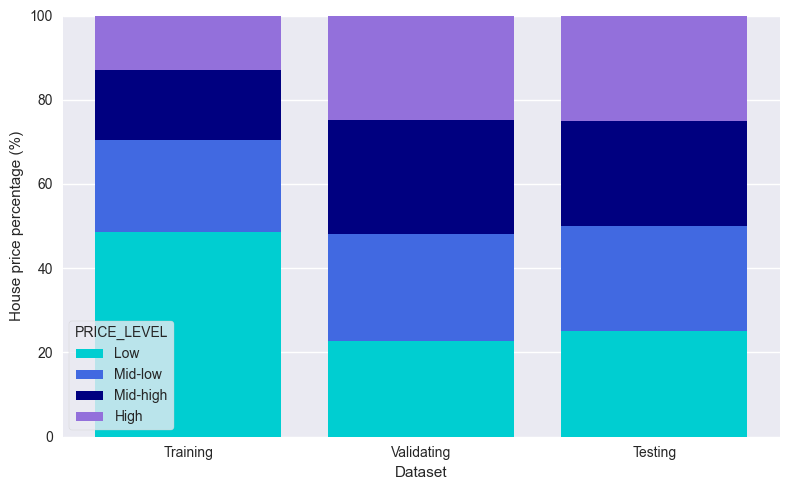

In [53]:
datasets = {
    "Training": train_data,
    "Validating": val_data,
    "Testing": test_data
}

# 沿用测试集的价格分档边界
_, price_bins = pd.qcut(
    test_errors["ACTUAL_PRICE"], q=4, retbins=True,
    duplicates="drop"
)
price_bins[0] = -np.inf
price_bins[-1] = np.inf

price_split_counts = pd.DataFrame(
    0, index=bin_names, columns=datasets.keys()
)

for name, data in datasets.items():
    levels = pd.cut(
        data["PRICE"],
        bins=price_bins,
        labels=bin_names,
        include_lowest=True
    )
    price_split_counts[name] = (
        levels.value_counts(sort=False).reindex(bin_names, fill_value=0)
    )

price_split_pct = price_split_counts.div(
    price_split_counts.sum(axis=0), axis=1
).mul(100)

x = range(len(price_split_pct.columns))
bottom = np.zeros(len(price_split_pct.columns))

plt.figure(figsize=(8, 5))
plt.style.use("seaborn-v0_8")

colors = ["darkturquoise", "royalblue", "navy", "mediumpurple"]

for level, color in zip(price_split_pct.index, colors):
    values = price_split_pct.loc[level].to_numpy()
    plt.bar(x, values, bottom=bottom, label=level, color=color)
    bottom += values

plt.xticks(x, price_split_pct.columns)
plt.xlabel("Dataset")
plt.ylabel("House price percentage (%)")
plt.ylim(0, 100)
plt.legend(title="PRICE_LEVEL", frameon=True)
plt.tight_layout()
plt.show()

从上图可以看出，训练集中的低价房占比较高，而验证集和测试集中的中高价房占比明显增加。这表明三个时间段的房价分布存在差异，可能反映了房价随时间变化，也可能与各时期成交房产的类型不同有关。

这一分布变化可能影响模型的泛化表现：模型主要从较早时期、低价房占比较高的训练数据中学习规律，面对后期较高价位的房产时，可能倾向于低估。误差分析中观察到的高价房低估、低价房高估与这一现象相符。

## 6.5 对房产交易进行随机切分的对照

为验证上述说法，本节对数据进行随机切分来评估模型表现。

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import numpy as np

# 随机切分 80% / 20%
random_train_data, random_test_data = train_test_split(
    price_data.dropna(subset=["PRICE_LOG10"]).copy(),
    test_size=0.2,
    random_state=42
)

# 按年份排好随机训练集，供模型函数使用
random_train_data = random_train_data.sort_values("SALE_YEAR")

# 暂存原来的时间切分训练集
original_train_data = train_data

try:
    train_data = random_train_data

    # 用 CLUSTER 特征组和 100 棵树训练
    linear_model, residual_model, features = fit_residual_model(
        selected_cat_cols, 100
    )
finally:
    # 恢复时间切分的训练集
    train_data = original_train_data

# 在随机留出的 20% 上评估
random_errors, random_mae = evaluate_residual_model(
    linear_model,
    residual_model,
    features,
    random_test_data
)

# 同一随机测试集上的中位数基线
baseline_price = 10 ** random_train_data["PRICE_LOG10"].median()
actual_prices = 10 ** random_test_data["PRICE_LOG10"]

random_baseline_mae = mean_absolute_error(
    actual_prices,
    np.full(len(random_test_data), baseline_price)
)

print(f"随机切分模型 MAE：${random_mae:,.0f}")
print(f"随机切分基线 MAE：${random_baseline_mae:,.0f}")
print(f"相对基线降低：{(random_baseline_mae - random_mae) / random_baseline_mae:.1%}")

随机切分模型 MAE：$319,026
随机切分基线 MAE：$661,336
相对基线降低：51.8%


随机切分后误差没有降低，说明把相似年份的交易同时放进训练集和测试集，并没有明显改善模型表现。这可能是因为模型误差主要来自房屋差异、缺失的房屋特征或极端房价，而不只是年份变化。

In [55]:
from sklearn.model_selection import train_test_split

random_train_data, random_test_data = train_test_split(
    price_data.dropna(subset=["PRICE_LOG10"]).copy(),
    test_size=0.2,
    random_state=42
)

# 按年份排好随机训练集，供模型函数使用
random_train_data = random_train_data.sort_values("SALE_YEAR")

# 暂存原来的时间切分训练集
original_train_data = train_data

try:
    train_data = random_train_data

    # 用 CLUSTER 特征组和 100 棵树训练
    linear_model, residual_model, features = fit_residual_model(
        selected_cat_cols, 100
    )
finally:
    # 恢复时间切分的训练集
    train_data = original_train_data

# 在随机留出的 20% 上评估
random_errors, random_mae = evaluate_residual_model(
    linear_model,
    residual_model,
    features,
    random_test_data
)

# 同一随机测试集上的中位数基线
baseline_price = 10 ** random_train_data["PRICE_LOG10"].median()
actual_prices = 10 ** random_test_data["PRICE_LOG10"]

random_baseline_mae = mean_absolute_error(
    actual_prices,
    np.full(len(random_test_data), baseline_price)
)

print(f"随机切分模型 MAE：${random_mae:,.0f}")
print(f"随机切分基线 MAE：${random_baseline_mae:,.0f}")
print(f"相对基线降低：{(random_baseline_mae - random_mae) / random_baseline_mae:.1%}")

随机切分模型 MAE：$319,026
随机切分基线 MAE：$661,336
相对基线降低：51.8%
